In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load SMS Spam Dataset

file_path = "../Dataset/SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("\nFirst 5 records:")
display(df.head())

Dataset loaded successfully!

First 5 records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# Dataset Information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nLabel Distribution:")
print(df["label"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (5572, 2)

Column Names:
Index(['label', 'message'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Label Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records: 403


In [4]:
# Step 16: Remove Duplicate Records

df_clean = df.drop_duplicates().copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nDuplicate Records After Cleaning:")
print(df_clean.duplicated().sum())

print("\nUpdated Label Distribution:")
print(df_clean["label"].value_counts())

Original Dataset Shape: (5572, 2)
Cleaned Dataset Shape: (5169, 2)

Duplicate Records After Cleaning:
0

Updated Label Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [5]:
# Step 17: Convert Labels into Numbers

df_clean["label_num"] = df_clean["label"].map({
    "ham": 0,
    "spam": 1
})

print("Label Conversion:")
print(df_clean[["label", "label_num"]].head(10))

print("\nConverted Label Counts:")
print(df_clean["label_num"].value_counts())

Label Conversion:
  label  label_num
0   ham          0
1   ham          0
2  spam          1
3   ham          0
4   ham          0
5  spam          1
6   ham          0
7   ham          0
8  spam          1
9  spam          1

Converted Label Counts:
label_num
0    4516
1     653
Name: count, dtype: int64


In [6]:
# Step 18: Separate Input and Output

X = df_clean["message"]
y = df_clean["label_num"]

print("Input Messages:")
print(X.head())

print("\nOutput Labels:")
print(y.head())

print("\nInput Shape:", X.shape)
print("Output Shape:", y.shape)

Input Messages:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: str

Output Labels:
0    0
1    0
2    1
3    0
4    0
Name: label_num, dtype: int64

Input Shape: (5169,)
Output Shape: (5169,)


In [7]:
# Step 19: Split Training and Testing Data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Labels:")
print(y_train.value_counts())

print("\nTesting Labels:")
print(y_test.value_counts())

Training Data Shape: (4135,)
Testing Data Shape: (1034,)

Training Labels:
label_num
0    3613
1     522
Name: count, dtype: int64

Testing Labels:
label_num
0    903
1    131
Name: count, dtype: int64


In [8]:
# Step 20: TF-IDF Vectorization

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=3000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Training Shape:", X_train_tfidf.shape)
print("TF-IDF Testing Shape:", X_test_tfidf.shape)

print("\nNumber of Features:", len(tfidf.get_feature_names_out()))

TF-IDF Training Shape: (4135, 3000)
TF-IDF Testing Shape: (1034, 3000)

Number of Features: 3000


In [9]:
# Step 21: Train Naive Bayes Model

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


In [10]:
# Step 22: Make Predictions

y_pred = model.predict(X_test_tfidf)

print("Predictions completed successfully!")

print("\nFirst 10 Actual Labels:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Labels:")
print(y_pred[:10])

Predictions completed successfully!

First 10 Actual Labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 Predicted Labels:
[0 0 0 0 0 0 0 0 0 0]


In [11]:
# Step 23: Model Evaluation

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

Model Accuracy: 97.38878143133462 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       903
        Spam       1.00      0.79      0.89       131

    accuracy                           0.97      1034
   macro avg       0.99      0.90      0.94      1034
weighted avg       0.97      0.97      0.97      1034



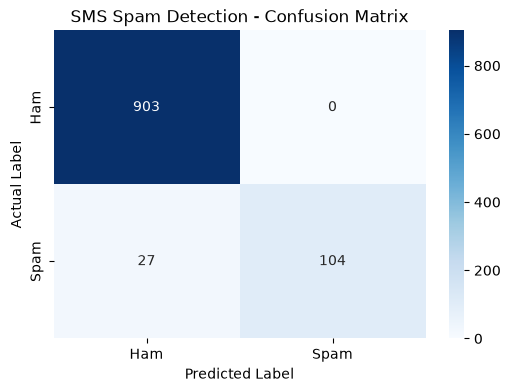

In [12]:
# Step 24: Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")

plt.show()

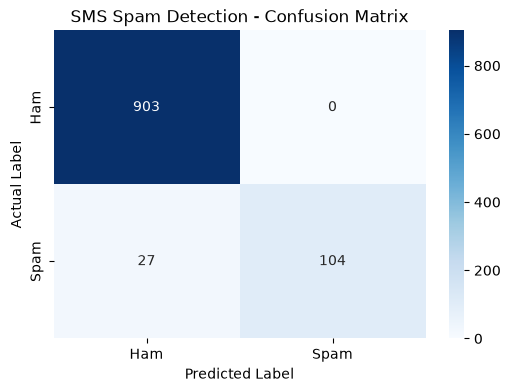

Confusion matrix saved successfully!


In [13]:
# Step 25: Save Confusion Matrix Graph

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SMS Spam Detection - Confusion Matrix")

plt.savefig(
    "../Graphs/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

In [14]:
# Step 26: Save Trained Model and TF-IDF Vectorizer

import pickle
from pathlib import Path

model_folder = Path("../Source_Code")
model_folder.mkdir(exist_ok=True)

with open(model_folder / "spam_model.pkl", "wb") as file:
    pickle.dump(model, file)

with open(model_folder / "tfidf_vectorizer.pkl", "wb") as file:
    pickle.dump(tfidf, file)

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


In [15]:
# Step 27: Save Model Evaluation Report

report = classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
)

with open("../Documentation/MODEL_EVALUATION_REPORT.txt", "w") as file:
    file.write("SMS SPAM DETECTION - MODEL EVALUATION\n\n")
    file.write(f"Accuracy: {accuracy * 100:.2f}%\n\n")
    file.write(report)
    file.write("\n\nConfusion Matrix:\n")
    file.write(str(cm))

print("Evaluation report saved successfully!")

Evaluation report saved successfully!


In [16]:
# Step 23: Model Evaluation

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

Model Accuracy: 97.38878143133462 %

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       903
        Spam       1.00      0.79      0.89       131

    accuracy                           0.97      1034
   macro avg       0.99      0.90      0.94      1034
weighted avg       0.97      0.97      0.97      1034



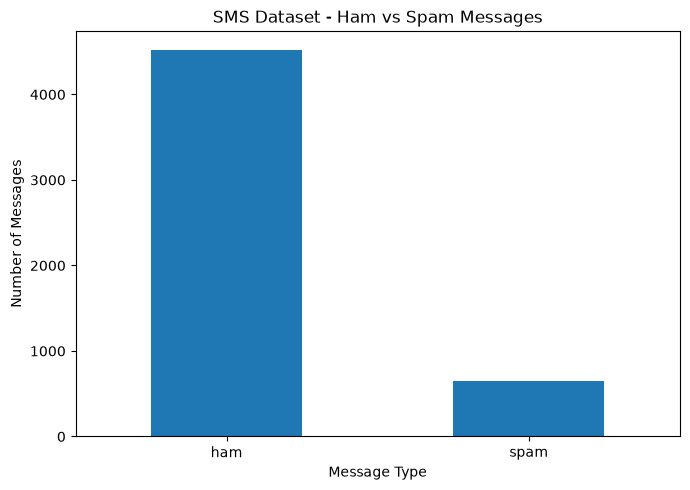

Class distribution graph saved successfully!


In [17]:
import matplotlib.pyplot as plt

label_counts = df_clean["label"].value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar")

plt.title("SMS Dataset - Ham vs Spam Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../Graphs/class_distribution.png", dpi=300)
plt.show()

print("Class distribution graph saved successfully!")

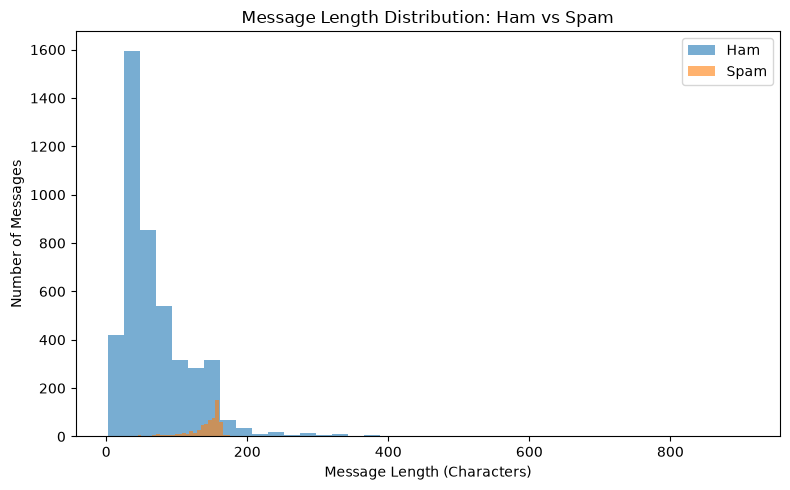

Message length graph saved successfully!


In [18]:
import matplotlib.pyplot as plt

df_clean["message_length"] = df_clean["message"].apply(len)

plt.figure(figsize=(8, 5))

plt.hist(
    df_clean[df_clean["label"] == "ham"]["message_length"],
    bins=40,
    alpha=0.6,
    label="Ham"
)

plt.hist(
    df_clean[df_clean["label"] == "spam"]["message_length"],
    bins=40,
    alpha=0.6,
    label="Spam"
)

plt.title("Message Length Distribution: Ham vs Spam")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Number of Messages")
plt.legend()
plt.tight_layout()

plt.savefig("../Graphs/message_length_distribution.png", dpi=300)
plt.show()

print("Message length graph saved successfully!")

In [19]:
from pathlib import Path

graph_folder = Path("../Graphs")

print("Saved graph files:")
for file in sorted(graph_folder.glob("*.png")):
    print(file.name)

Saved graph files:
class_distribution.png
confusion_matrix.png
message_length_distribution.png
